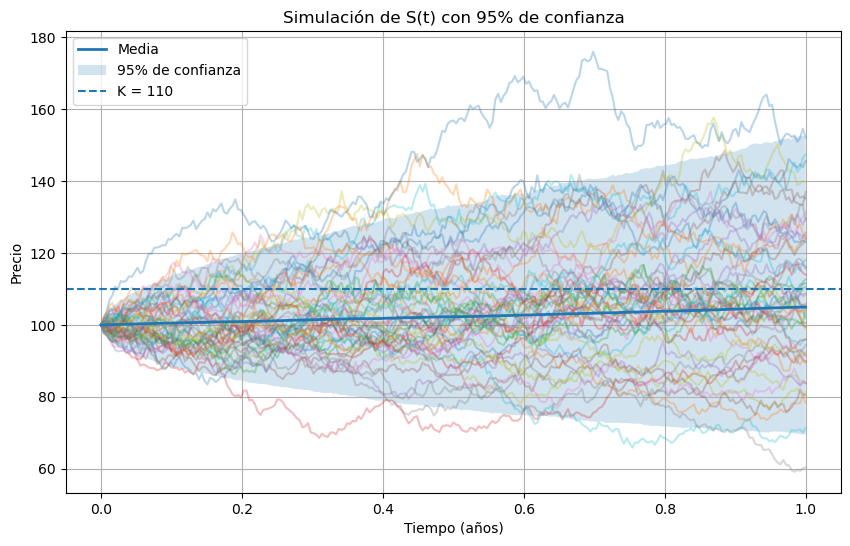

In [50]:
import numpy as np
import matplotlib.pyplot as plt 

np.random.seed(42)

# Parámetros
S0 = 100
K = 110
r = 0.05
sigma = 0.20
T = 1
M = 10000

#Numero de pasos 
N = 252
dt = T/N

S = np.zeros((M, N+1))

#precio incial 

S[:,0] = S0

# Simulación durante todo el año
for t in range(1, N + 1):
    
    Z = np.random.normal(0, 1, M)
    
    S[:, t] = S[:, t-1] * np.exp(
        (r - (sigma**2)/2) * dt
        + sigma * np.sqrt(dt) * Z
    )

# Tiempo
tiempo = np.linspace(0, T, N + 1)

# Percentiles del 95%
P2_5 = np.percentile(S, 2.5, axis=0)
P97_5 = np.percentile(S, 97.5, axis=0)

# Media
media = np.mean(S, axis=0)

# Gráfica
plt.figure(figsize=(10,6))

# Simulaciones
for i in range(50):
    plt.plot(tiempo, S[i,:], alpha=0.3)

# linea de Media
plt.plot(tiempo, media, linewidth=2, label='Media')

# Intervalo 95%
plt.fill_between(
    tiempo,
    P2_5,
    P97_5,
    alpha=0.2,
    label='95% de confianza'
)

# Strike
plt.axhline(K, linestyle='--', label='K = 110')

plt.xlabel('Tiempo (años)')
plt.ylabel('Precio')
plt.title('Simulación de S(t) con 95% de confianza')
plt.legend()
plt.grid()
plt.show()

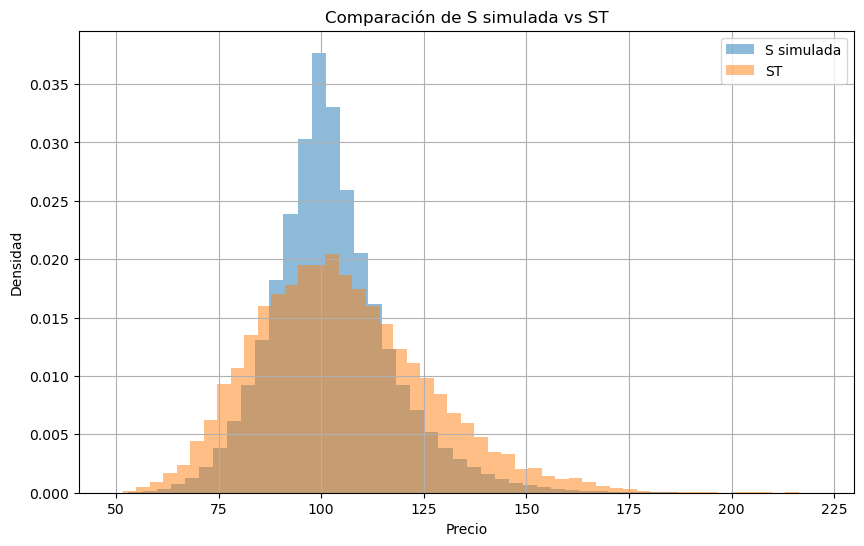

In [51]:
plt.figure(figsize=(10,6))

plt.hist(S.flatten(), bins=50, density=True, alpha=0.5, label='S simulada')
plt.hist(ST, bins=50, density=True, alpha=0.5, label='ST')

plt.xlabel('Precio')
plt.ylabel('Densidad')
plt.title('Comparación de S simulada vs ST')
plt.legend()
plt.grid()

plt.show()

In [52]:
# CALL EUROPEA

ST = S[:, -1]

payoff_europeo = np.maximum(ST - K, 0)

# Valor presente
VP_europeo = payoff_europeo * np.exp(-r*T)

# Promedio
precio_europeo = np.mean(VP_europeo)



# CALL ASIÁTICA

S_promedio = np.mean(S[:, 1:], axis=1)

payoff_asiatico = np.maximum(S_promedio - K, 0)

# Valor presente
VP_asiatico = payoff_asiatico * np.exp(-r*T)

# Promedio
precio_asiatico = np.mean(VP_asiatico)



In [53]:
print("Call Europea:")
print("Valor presente:", precio_europeo)

print("\nCall Asiática:")
print("Valor presente:", precio_asiatico)

Call Europea:
Valor presente: 5.952682333866707

Call Asiática:
Valor presente: 1.9067555779079357


### Simulación con 1k trayectorias 

In [55]:
M = 1000 

S = np.zeros((M,N+1))
    

#precio inicial 

S[:,0] = S0

#simulación 

for t in range(1,N+1):
    
    Z = np.random.normal(0,1,M)
    
    S[:,t] = S[:,t-1] * np.exp(
        (r - (sigma**2)/2) * dt + sigma * np.sqrt(dt)*Z
    )
    

In [56]:
promedio_S = np.mean(S[:, 1:], axis=1)

print("Primeros 10 promedios de trayectoria:")
print(promedio_S[:10])

Primeros 10 promedios de trayectoria:
[105.677752    93.50282568 118.57904887 125.01588495  94.17756333
 105.87539851  96.81365316 110.91656944  97.64861982 127.00317306]


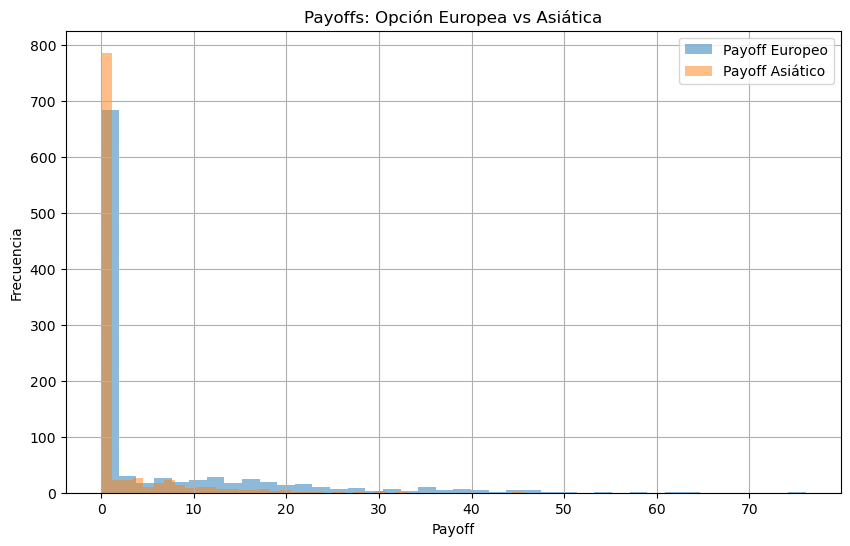

In [76]:
# PAYOFF OPCIÓN EUROPEA
ST = S[:, -1]

payoff_europea = np.maximum(ST - K, 0)

# PAYOFF OPCIÓN ASIÁTICA

payoff_asiatica = np.maximum(promedio_S - K, 0)



# HISTOGRAMA DE PAYOFFS

plt.figure(figsize=(10,6))

plt.hist(
    payoff_europea,
    bins=40,
    alpha=0.5,
    label='Payoff Europeo'
)

plt.hist(
    payoff_asiatica,
    bins=40,
    alpha=0.5,
    label='Payoff Asiático'
)

plt.xlabel('Payoff')
plt.ylabel('Frecuencia')
plt.title('Payoffs: Opción Europea vs Asiática')
plt.legend()
plt.grid()
plt.show()

### precio de las opciones 

In [77]:
precio_europea = np.exp(-r*T) * np.mean(payoff_europea)

precio_asiatica = np.exp(-r*T) * np.mean(payoff_asiatica)


print("Precio opción europea:", precio_europea)
print("Precio opción asiática:", precio_asiatica)

Precio opción europea: 5.416268389882404
Precio opción asiática: 1.821036574126679
